# Tokenization

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 23.04.2024
- Date of Last Modification: 03.05.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import scgpt as scg
import squidpy as sq
import torch
from datasets import load_from_disk
from scipy.stats import spearmanr
from scgpt.model import TransformerModel
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from skmisc.loess import loess

from nichejepa import tokenizers
from nichejepa import utils

/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


### 1.2 Run Notebook Setup

In [3]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
cell_gene_means_dictionary_file = "../datasets/cell_gene_means_dictionary.pkl"
cell_gene_reg_stds_dictionary_file = "../datasets/cell_gene_reg_stds_dictionary.pkl"
neighborhood_gene_means_dictionary_file = "../datasets/neighborhood_gene_means_dictionary.pkl"
neighborhood_gene_reg_stds_dictionary_file = "../datasets/neighborhood_gene_reg_stds_dictionary.pkl"
geneformer_token_dictionary_file = "../datasets/geneformer_token_dictionary.pkl"
nichejepa_token_dictionary_file = "../datasets/token_dictionary.pkl"

dataset_cache_file = "../datasets/scgpt_gene_embeddings_dataset"

scgpt_model_dir = Path("../scgpt/pretrained_model")
scgpt_model_config_file = scgpt_model_dir / "args.json"
scgpt_model_file = scgpt_model_dir / "best_model.pt"
scgpt_vocab_file = scgpt_model_dir / "vocab.json"
scgpt_metadata_file = Path("../scgpt/metadata/gene_info.csv")

## 2. Tokenization

In [5]:
dataset_name = "nanostring_cosmx_human_brain"

In [6]:
# Load data
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}.h5ad")

### 2.1 Create Token Dictionary

In [7]:
### Create token dict for nichejepa with cell and neighborhood tokens ###

# Load geneformer token dict to get protein-coding and miRNA genes
with open(geneformer_token_dictionary_file, "rb") as f:
    token_dict = pickle.load(f)

# Add cls token
def insert_at_index(d, index, key, value):
    items = list(d.items())
    items.insert(index, (key, value))
    new_d = dict(items)
    return new_d
token_dict = insert_at_index(token_dict, 2, "<cls_cell>", 2)
token_dict = insert_at_index(token_dict, 3, "<cls_neighborhood>", 3)

# Remove genes not in dataset
gene_list = adata.var["ensembl_id"].tolist()
token_dict_copy = token_dict.copy()
for token in token_dict_copy.keys():
    if "ENS" in token and token not in gene_list:
        del(token_dict[token])
del(token_dict_copy)

# Separate gene tokens into cell and neighborhood tokens
new_token_dict = {
    (key + "_cell" if "ENS" in key else key): value
    for value, key in enumerate(token_dict.keys())}
new_token_dict_copy = new_token_dict.copy()
i = 0
for key in new_token_dict_copy.keys():
    if "ENS" in key:
        new_token_dict[key.replace("cell", "neighborhood")] = len(new_token_dict_copy) + i
        i += 1
del(new_token_dict_copy)

# Write to disk
with open(nichejepa_token_dictionary_file, "wb") as file:
    pickle.dump(new_token_dict, file)

In [ ]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

In [8]:
# NicheJEPA token dict
token_dict

{'<pad>': 0,
 '<mask>': 1,
 '<cls_cell>': 2,
 '<cls_neighborhood>': 3,
 'ENSG00000000938_cell': 4,
 'ENSG00000000971_cell': 5,
 'ENSG00000001036_cell': 6,
 'ENSG00000001084_cell': 7,
 'ENSG00000001167_cell': 8,
 'ENSG00000001561_cell': 9,
 'ENSG00000002016_cell': 10,
 'ENSG00000002330_cell': 11,
 'ENSG00000002745_cell': 12,
 'ENSG00000002746_cell': 13,
 'ENSG00000002822_cell': 14,
 'ENSG00000003056_cell': 15,
 'ENSG00000003096_cell': 16,
 'ENSG00000003147_cell': 17,
 'ENSG00000003400_cell': 18,
 'ENSG00000003402_cell': 19,
 'ENSG00000003436_cell': 20,
 'ENSG00000003509_cell': 21,
 'ENSG00000003756_cell': 22,
 'ENSG00000003987_cell': 23,
 'ENSG00000003989_cell': 24,
 'ENSG00000004059_cell': 25,
 'ENSG00000004468_cell': 26,
 'ENSG00000004487_cell': 27,
 'ENSG00000004660_cell': 28,
 'ENSG00000004700_cell': 29,
 'ENSG00000004776_cell': 30,
 'ENSG00000004779_cell': 31,
 'ENSG00000004799_cell': 32,
 'ENSG00000004897_cell': 33,
 'ENSG00000004948_cell': 34,
 'ENSG00000005020_cell': 35,
 'ENSG0

In [9]:
# First cell gene token
token_dict["ENSG00000000938_cell"]

4

In [10]:
# First neighborhood gene token
token_dict["ENSG00000000938_neighborhood"]

6035

### 2.2 Compute Normalization Factors for Gene Counts

Corpus Means and Regularized Standard Deviations are used depending on the 'norm_method' specified in the STRankTokenizer (check source code).

#### 2.2.1 Compute Corpus Means and Regularized Standard Deviations for Cell and Neighborhood Genes

In [ ]:
norm_method = ""

In [ ]:
# Normalize cell gene counts by read depth
read_depth_norm_counts = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000

# Compute means and vars of read-depth normalized cell gene counts
cell_gene_means = np.mean(read_depth_norm_counts, axis=0)
cell_gene_vars = np.var(read_depth_norm_counts, axis=0)

In [ ]:
# Normalize neighborhood gene counts by read depth
read_depth_norm_counts_neighborhood = (adata.layers["counts_neighborhood"] /
                                       adata.layers["counts_neighborhood"].sum(1).reshape(-1, 1)
                                       * 10000)

# Compute means and vars of read-depth normalized neighborhood gene counts
neighborhood_gene_means = np.mean(read_depth_norm_counts_neighborhood, axis=0)
neighborhood_gene_vars = np.var(read_depth_norm_counts_neighborhood, axis=0)

In [ ]:
# Learn mean-variance relationships for cell and neighborhood genes respectively
# to remove (only) expected variance based on mean to stabilize variances across genes.
# Inspired by seurat scaling to determine highly variable genes
# https://github.com/scverse/scanpy/blob/4642cf8e2e51b257371792cb4fcb9611c0a81123/scanpy/preprocessing/_highly_variable_genes.py#L26
not_const_cell_genes = cell_gene_vars > 0
cell_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
y = np.log10(cell_gene_vars[not_const_cell_genes])
x = np.log10(cell_gene_means[not_const_cell_genes])
cell_gene_model = loess(x, y, span=0.3, degree=2)
cell_gene_model.fit()
cell_gene_est_log_vars[not_const_cell_genes] = cell_gene_model.outputs.fitted_values
cell_gene_reg_stds = np.sqrt(10**cell_gene_est_log_vars)

not_const_neighborhood_genes = neighborhood_gene_vars > 0
neighborhood_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
y = np.log10(neighborhood_gene_vars[not_const_neighborhood_genes])
x = np.log10(neighborhood_gene_means[not_const_neighborhood_genes])
neighborhood_gene_model = loess(x, y, span=0.3, degree=2)
neighborhood_gene_model.fit()
neighborhood_gene_est_log_vars[not_const_neighborhood_genes] = neighborhood_gene_model.outputs.fitted_values
neighborhood_gene_reg_stds = np.sqrt(10**neighborhood_gene_est_log_vars)

In [ ]:
# Create norm factor dictionaries for tokenizer and store on disk
cell_gene_means_dict = {}
cell_gene_reg_stds_dict = {}
neighborhood_gene_means_dict = {}
neighborhood_gene_reg_stds_dict = {}

for gene, cell_gene_mean, cell_gene_reg_std, neighborhood_gene_mean, neighborhood_gene_reg_std in zip(
        adata.var["ensembl_id"].values,
        cell_gene_means,
        cell_gene_reg_stds,
        neighborhood_gene_means,
        neighborhood_gene_reg_stds):
    cell_gene_means_dict[gene] = cell_gene_mean
    cell_gene_reg_stds_dict[gene] = cell_gene_reg_std
    neighborhood_gene_means_dict[gene] = neighborhood_gene_mean
    neighborhood_gene_reg_stds_dict[gene] = neighborhood_gene_reg_std

with open(cell_gene_means_dictionary_file, "wb") as file:
    pickle.dump(cell_gene_means_dict, file)
with open(cell_gene_reg_stds_dictionary_file, "wb") as file:
    pickle.dump(cell_gene_reg_stds_dict, file)
with open(neighborhood_gene_means_dictionary_file, "wb") as file:
    pickle.dump(neighborhood_gene_means_dict, file)
with open(neighborhood_gene_reg_stds_dictionary_file, "wb") as file:
    pickle.dump(neighborhood_gene_reg_stds_dict, file)

#### 2.2.2 Test Normalization

In [ ]:
# Keep only protein-coding and miRNA genes
vocab = list(token_dict.keys())
coding_miRNA_ids = [
    key.split("_")[0] for key in list(vocab) if "_cell" in key]
coding_miRNA_dict = dict(zip(coding_miRNA_ids, [True] * len(vocab)))
coding_miRNA_idx = np.where(
    [coding_miRNA_dict.get(gene_id, False) for gene_id in adata.var["ensembl_id"]])[0]
coding_miRNA_adata = adata[:, coding_miRNA_idx]

In [ ]:
# Load cell and neighborhood gene corpus means and vars
with open(cell_gene_means_dictionary_file, "rb") as f:
    cell_gene_means_dict = pickle.load(f)
with open(cell_gene_reg_stds_dictionary_file, "rb") as f:
    cell_gene_reg_stds_dict = pickle.load(f)
with open(neighborhood_gene_means_dictionary_file, "rb") as f:
    neighborhood_gene_means_dict = pickle.load(f)
with open(neighborhood_gene_reg_stds_dictionary_file, "rb") as f:
    neighborhood_gene_reg_stds_dict = pickle.load(f)

cell_gene_means = np.array(
    [cell_gene_means_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])
cell_gene_reg_stds = np.array(
    [cell_gene_reg_stds_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])
neighborhood_gene_means = np.array(
    [neighborhood_gene_means_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])
neighborhood_gene_reg_stds = np.array(
    [neighborhood_gene_reg_stds_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])

In [ ]:
# Compute mean std normalized counts where std is exc
read_depth_norm_counts = coding_miRNA_adata.X / coding_miRNA_adata.X.sum(1).reshape(-1, 1) * 10000
mean_std_norm_counts = (read_depth_norm_counts - cell_gene_means) / cell_gene_reg_stds

In [ ]:
read_depth_norm_counts_neighborhood = (
    coding_miRNA_adata.layers["counts_neighborhood"] /
    coding_miRNA_adata.layers["counts_neighborhood"].sum(1).reshape(-1, 1) * 10000)
mean_std_norm_counts_neighborhood = (
    read_depth_norm_counts_neighborhood - neighborhood_gene_means) / neighborhood_gene_reg_stds

### 2.3 Run Tokenizer

In [14]:
tk = tokenizers.STRankTokenizer(
    norm_method="analytic_pearson_residuals",
    #cell_gene_means_file=cell_gene_means_dictionary_file,
    #cell_gene_reg_stds_file=cell_gene_reg_stds_dictionary_file,
    #neighborhood_gene_means_file=neighborhood_gene_means_dictionary_file,
    #neighborhood_gene_reg_stds_file=neighborhood_gene_reg_stds_dictionary_file,
    token_dictionary_file=nichejepa_token_dictionary_file,
    custom_attr_name_dict={"cell_type": "cell_types",
                           "niche_type": "niche_types"})

In [15]:
tk.tokenize_data(input_directory=st_data_silver_folder_path,
                 output_directory=st_data_gold_folder_path,
                 output_file_prefix=dataset_name)

Tokenizing '../datasets/st_data/silver/nanostring_cosmx_human_brain.h5ad'...
'../datasets/st_data/silver/nanostring_cosmx_human_brain.h5ad' has no column 'filter_pass'; utilizing all cells.
Creating Hugging Face dataset...


Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

Saving the dataset (0/10 shards):   0%|          | 0/188686 [00:00<?, ? examples/s]

### 2.4 Evaluate Tokenizer

In [8]:
# Load tokenized dataset
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{dataset_name}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

In [9]:
# Get cell and neighborhood gene token rankings
gene_token_ranking = np.array(dataset["input_ids"])
adata.obsm["cell_gene_token_ranking"] = gene_token_ranking[:, 1:1024]
adata.obsm["neighborhood_gene_token_ranking"] = gene_token_ranking[:, 1025:]

In [ ]:
# Validate
gene_idx = np.argmax(mean_std_norm_counts, axis=1)[0]
print(coding_miRNA_adata.var["ensembl_id"][gene_idx])
gene_token_idx = coding_miRNA_adata.obsm["cell_gene_token_ranking"][0][0]
print(token_dict_reverse[gene_token_idx])

gene_idx = np.argmax(mean_std_norm_counts_neighborhood, axis=1)[0]
print(coding_miRNA_adata.var["ensembl_id"][gene_idx])
gene_token_idx = coding_miRNA_adata.obsm["neighborhood_gene_token_ranking"][0][0]
print(token_dict_reverse[gene_token_idx])

#### 2.4.1 Cell Type Classification

Task: cell type classification using scGPT embedded top ranked genes.

In [10]:
### Get scGPT gene embeddings for each gene Ensembl id ###

# Set config
pad_token = "<pad>"
special_tokens = [pad_token, "<cls>", "<eoc>"]
pad_value = -2
n_input_bins = 51

# Get vocab
scgpt_vocab = GeneVocab.from_file(scgpt_vocab_file)
for s in special_tokens:
    if s not in scgpt_vocab:
        scgpt_vocab.append_token(s)

# Retrieve model parameters from config files
with open(scgpt_model_config_file, "r") as f:
    model_configs = json.load(f)
print(f"Resume model from {scgpt_model_file}, the model args will override the "
      f"config {scgpt_model_config_file}.")
embsize = model_configs["embsize"]
nhead = model_configs["nheads"]
d_hid = model_configs["d_hid"]
nlayers = model_configs["nlayers"]
n_layers_cls = model_configs["n_layers_cls"]

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ntokens = len(scgpt_vocab)  # size of vocabulary
model = TransformerModel(ntokens,
                         embsize,
                         nhead,
                         d_hid,
                         nlayers,
                         vocab=scgpt_vocab,
                         pad_value=pad_value,
                         n_input_bins=n_input_bins,)

try:
    model.load_state_dict(torch.load(scgpt_model_file))
    print(f"Loading all model params from {scgpt_model_file}")
except:
    model_dict = model.state_dict()
    pretrained_dict = torch.load(scgpt_model_file)
    pretrained_dict = {k: v
                       for k, v in pretrained_dict.items()
                       if k in model_dict and v.shape == model_dict[k].shape}
    for k, v in pretrained_dict.items():
        print(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model.to(device)

# Create mapping from Ensembl id to scGPT token id
gene2idx = scgpt_vocab.get_stoi()

metadata_df = pd.read_csv(scgpt_metadata_file)

ensemblid_mapping = dict(zip(metadata_df["feature_name"], metadata_df["feature_id"]))
ensemblid2idx = {ensemblid_mapping[k]: v for k, v in gene2idx.items() if k in ensemblid_mapping}

# Retrieve the data-independent gene embeddings from scGPT
gene_ids = np.array([id for id in ensemblid2idx.values()])
gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
gene_embeddings = gene_embeddings.detach().cpu().numpy()

# Store gene embeddings with Ensembl id
emsemblid_embedding_mapping = {}
for i, (key, val) in enumerate(ensemblid2idx.items()):
    emsemblid_embedding_mapping[key] = gene_embeddings[i, :]

Resume model from ../scgpt/pretrained_model/best_model.pt, the model args will override the config ../scgpt/pretrained_model/args.json.
Loading params encoder.embedding.weight with shape torch.Size([60697, 512])
Loading params encoder.enc_norm.weight with shape torch.Size([512])
Loading params encoder.enc_norm.bias with shape torch.Size([512])
Loading params value_encoder.linear1.weight with shape torch.Size([512, 1])
Loading params value_encoder.linear1.bias with shape torch.Size([512])
Loading params value_encoder.linear2.weight with shape torch.Size([512, 512])
Loading params value_encoder.linear2.bias with shape torch.Size([512])
Loading params value_encoder.norm.weight with shape torch.Size([512])
Loading params value_encoder.norm.bias with shape torch.Size([512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.weight with shape torch.Size([512, 512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.bias with shape torch.Size([512])
Loading params tran

In [11]:
# Get scgpt gene embeddings for NicheJEPA input token ids
def get_scgpt_gene_embeddings(example):
    example["tokens"] = [
        token_dict_reverse[token_id].replace("_cell", "").replace("_neighborhood", "")
        for token_id in example["input_ids"] if "ENS" in token_dict_reverse[token_id]]
    example["scgpt_gene_embeddings"] = [
        emsemblid_embedding_mapping.get(token, np.zeros(512, dtype=np.float32))
        for token in example["tokens"]]                     
    return example

dataset = dataset.map(
    get_scgpt_gene_embeddings, cache_file_name=dataset_cache_file)

# Save to disk
new_folder_path = tokenized_data_folder_path.replace("nanostring_cosmx_human_brain", "nanostring_cosmx_human_brain_processed")
dataset.save_to_disk(new_folder_path)

Saving the dataset (0/1609 shards):   0%|          | 0/188686 [00:00<?, ? examples/s]

In [ ]:
dataset["scgpt_gene_embeddings"][0]

In [12]:
import tqdm

In [13]:
scores = dict()
for i in tqdm(range(model.config.n_layer + 1)):
    # fit linear classifier
    lr_clf = LogisticRegression(max_iter=1000)
    lr_clf.fit(dataset["scgpt_gene_embeddings"], dataset["cell_type"])

    score = lr_clf.score(dataset["scgpt_gene_embeddings"], dataset["cell_type"])
    print(score)

AttributeError: 'TransformerModel' object has no attribute 'config'

In [ ]:
dataset["scgpt_gene_embeddings"][0]

In [ ]:
dataset["scgpt_gene_embeddings"][0]

In [ ]:
dataset["tokens"][0]

In [ ]:
dataset["tokens"][0]

In [ ]:
# Train classifier
train_dataset = encoded_dataset['train']
test_dataset = encoded_dataset['test']

scores = dict()
for i in tqdm(range(model.config.n_layer + 1)):
    # fit linear classifier
    lr_clf = LogisticRegression(max_iter=1000)
    lr_clf.fit(train_dataset[f'features_{i}'], train_dataset['label'])
    # compute accuracy on training + test set
    training_score = lr_clf.score(train_dataset[f'features_{i}'], train_dataset['label'])
    test_score = lr_clf.score(test_dataset[f'features_{i}'], test_dataset['label'])
    scores[f'features_{i}'] = (training_score, test_score)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(dataset["input_ids"], dataset["cell_type"], test_size=0.1, random_state=42, stratify=dataset["cell_type"])

In [ ]:
encoded_dataset["input_tokens"][0]

#### 2.4.2 Neighborhood Ranking

In [34]:
# Normalize counts as per https://www.sc-best-practices.org/preprocessing_visualization/normalization.html
sc.pp.log1p(adata)

In [ ]:
# Compute spatial autocorrelation score
sq.gr.spatial_autocorr(adata)
if "I" in adata.var.columns:
    del(adata.var["I"])
adata.var = adata.var.join(adata.uns["moranI"][["I"]], how="left")

In [33]:
adata.X

array([[1, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [1, 0, 0, ..., 0, 1, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

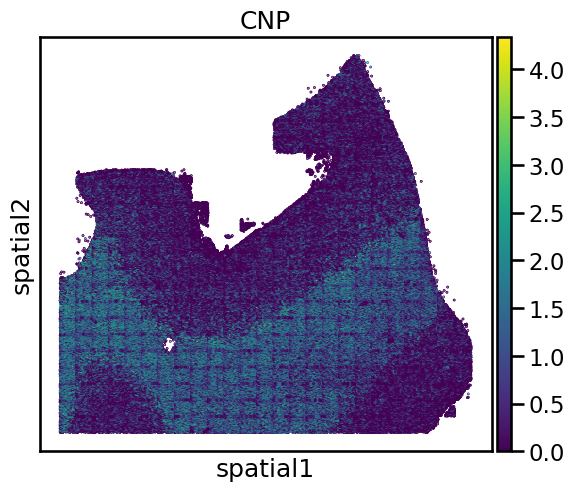

In [38]:
sq.pl.spatial_scatter(adata, color="CNP", shape=None) 

In [ ]:
sq.pl.spatial_scatter(adata, layer="counts", color="MBP", shape=None) 

In [ ]:
sq.pl.spatial_scatter(adata, layer="counts_neighborhood", color="MBP", shape=None) 

In [30]:
adata.var["neigborhood_gene_rank_sums"].sort_values(ascending=False)

PLP1        444405.0
MBP         402673.0
GFAP        293008.0
CNP         179752.0
NRGN        165190.0
              ...   
TRBC2            NaN
TRBV12-3         NaN
TRBV7-9          NaN
TRDC             NaN
TRGC1            NaN
Name: neigborhood_gene_rank_sums, Length: 6078, dtype: float64

In [22]:
# Sum up ranks for each neighborhood gene token
neighborhood_gene_token_rank_sums = {}

for i, row in enumerate(adata.obsm["neighborhood_gene_token_ranking"]):
    for rank, token in enumerate(row[:10]):
        if token in neighborhood_gene_token_rank_sums:
            neighborhood_gene_token_rank_sums[token] += (10 - rank)
        else:
            neighborhood_gene_token_rank_sums[token] = (10 - rank)

# Replace gene token by gene ensembl id
neighborhood_gene_rank_sums = {}

for key, value in token_dict.items():
    if value in neighborhood_gene_token_rank_sums:
        neighborhood_gene_rank_sums[key.replace("_neighborhood", "")] = neighborhood_gene_token_rank_sums[value]

neighborhood_gene_rank_file = f"../datasets/temp/{dataset_name}/neighborhood_gene_rank_sums.pkl"

with open(neighborhood_gene_rank_file, "wb") as file:
    pickle.dump(neighborhood_gene_rank_sums, file)

In [23]:
# Sum up ranks for each cell gene token
cell_gene_token_rank_sums = {}

for i, row in enumerate(adata.obsm["cell_gene_token_ranking"]):
    for rank, token in enumerate(row[:10]):
        if token in cell_gene_token_rank_sums:
            cell_gene_token_rank_sums[token] += (10 - rank)
        else:
            cell_gene_token_rank_sums[token] = (10 - rank)

# Replace gene token by gene ensembl id
cell_gene_rank_sums = {}

for key, value in token_dict.items():
    if value in cell_gene_token_rank_sums:
        cell_gene_rank_sums[key.replace("_cell", "")] = cell_gene_token_rank_sums[value]

cell_gene_rank_file = f"../datasets/temp/{dataset_name}/cell_gene_rank_sums.pkl"

with open(cell_gene_rank_file, "wb") as file:
    pickle.dump(cell_gene_rank_sums, file)

In [24]:
adata.var["neigborhood_gene_rank_sums"] = adata.var["ensembl_id"].map(neighborhood_gene_rank_sums)
adata.var["cell_gene_rank_sums"] = adata.var["ensembl_id"].map(cell_gene_rank_sums)

In [ ]:
#adata.var["neigborhood_gene_rank_sums"] = adata.var["neigborhood_gene_rank_sums"].fillna(0)
#adata.var["cell_gene_rank_sums"] = adata.var["cell_gene_rank_sums"].fillna(0)

In [ ]:
correlation, p_value = spearmanr(adata.var["neigborhood_gene_rank_sums"],
                                 adata.var["I"])
print("Spearman Correlation Coefficient:", correlation)
print("P-value:", p_value)

In [ ]:
running_corr = []
running_p_value = []

for i in range(norm_counts_neighborhood.shape[0]):
    i_corr, i_p_value = spearmanr(norm_counts_neighborhood[i],
                                  adata.var["I"])
running_corr.append(i_corr)
running_p_value.append(i_p_value)

corr = np.mean(running_corr)

print("Spearman Correlation Coefficient:", corr)
#print("P-value:", p_value)